<a href="https://colab.research.google.com/github/ayispibri/Data-Mining/blob/main/Studi_Kasus_Klasifikasi_Bank_Marketing_Tugas_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus Klasifikasi Machine Learning: Prediksi Nasabah Berlangganan Deposito

**Nama:** Ayis Pibri Setyanto  
**NIM:** 2404010027  
**Mata kuliah:** Data Mining

## 1. Latar Belakang dan Permasalahan
Bank melakukan kampanye pemasaran melalui telepon untuk menawarkan deposito berjangka. Tidak semua nasabah menerima tawaran tersebut. Jika bank dapat memperkirakan nasabah yang lebih berpotensi berlangganan, kampanye dapat diarahkan dengan lebih efisien. Studi ini membangun model klasifikasi biner untuk memprediksi apakah nasabah berlangganan deposito (`yes`) atau tidak (`no`). Prediksi hanya digunakan sebagai alat bantu, bukan pengganti keputusan manusia.

## 2. Dataset
Dataset **Bank Marketing** berasal dari UCI Machine Learning Repository dan berisi catatan kampanye pemasaran sebuah institusi perbankan di Portugal. Versi `bank-full.csv` berisi 45.211 baris dan 17 kolom, termasuk target `y`. Data diunduh langsung dari repositori UCI pada saat notebook dijalankan. https://archive.ics.uci.edu/dataset/222/bank

Referensi dataset: Moro, S., Cortez, P., & Rita, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

## 3. Metode
Model utama adalah **Random Forest**, yaitu gabungan banyak pohon keputusan yang hasilnya digabungkan untuk menghasilkan prediksi. **Logistic Regression** digunakan sebagai pembanding sederhana. Data dibagi menjadi data latih 80% dan data uji 20% dengan stratifikasi target. Fitur kategori diubah dengan One-Hot Encoding. Evaluasi menggunakan precision, recall, F1-score, ROC-AUC, dan confusion matrix. Karena kelas `yes` biasanya jauh lebih sedikit daripada `no`, akurasi saja tidak cukup untuk menilai model.

Catata: kolom `duration` (durasi panggilan) dikeluarkan karena durasi panggilan baru diketahui setelah panggilan berlangsung dan dapat membuat prediksi sebelum menghubungi nasabah menjadi tidak realistis. Kolom ini berisiko menimbulkan kebocoran informasi untuk tujuan prediksi awal kampanye.


## 4. Persiapan pustaka dan pengunduhan dataset


In [1]:
import io, zipfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

url = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
with urllib.request.urlopen(url) as response:
    outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

print('Isi arsip UCI:', outer_zip.namelist())
bank_zip_name = next(name for name in outer_zip.namelist() if name.endswith('bank.zip') and 'additional' not in name)
bank_zip_bytes = outer_zip.read(bank_zip_name)
with zipfile.ZipFile(io.BytesIO(bank_zip_bytes)) as bank_zip:
    csv_name = next(name for name in bank_zip.namelist() if name.endswith('bank-full.csv'))
    with bank_zip.open(csv_name) as f:
        df = pd.read_csv(f, sep=';')

print('Ukuran dataset:', df.shape)
display(df.head())


Isi arsip UCI: ['bank.zip', 'bank-additional.zip']
Ukuran dataset: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 5. Memahami dan mengeksplorasi data


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Jumlah nilai kosong per kolom:


,missing
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Distribusi target:


,jumlah
y,
no,39922
yes,5289


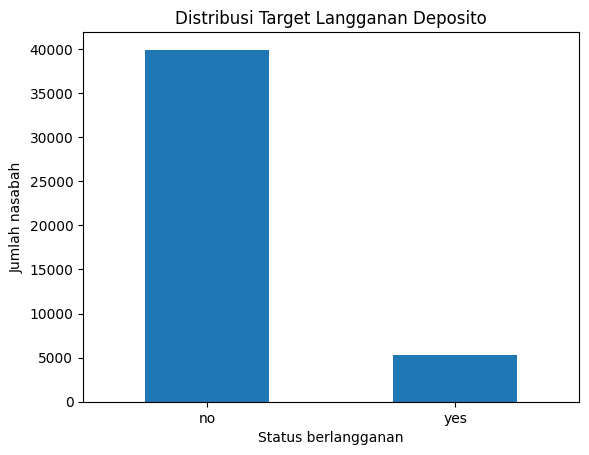

In [2]:
print('Informasi dataset:')
df.info()
print('\nJumlah nilai kosong per kolom:')
display(df.isna().sum().to_frame('missing'))
print('\nDistribusi target:')
display(df['y'].value_counts().to_frame('jumlah'))

df['y'].value_counts().reindex(['no','yes']).plot(kind='bar')
plt.title('Distribusi Target Langganan Deposito')
plt.xlabel('Status berlangganan')
plt.ylabel('Jumlah nasabah')
plt.xticks(rotation=0)
plt.show()


## 6. Pra-pemrosesan dan pembagian data
Target `y` diubah menjadi label kelas. Fitur numerik diisi menggunakan median dan distandardisasi untuk menjaga skala yang sebanding, sedangkan fitur kategorikal diisi menggunakan modus dan diubah menjadi variabel indikator. Semua tahap pemrosesan dipasang di dalam pipeline agar parameter pemrosesan dipelajari hanya dari data latih.


In [3]:
# Hapus duration untuk menghindari fitur yang baru diketahui setelah panggilan selesai.
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Data latih:', X_train.shape)
print('Data uji:', X_test.shape)
print('\nProporsi kelas data latih:')
display(y_train.value_counts(normalize=True).rename(index={0:'no', 1:'yes'}))


Data latih: (36168, 15)
Data uji: (9043, 15)

Proporsi kelas data latih:


,proportion
y,
no,0.883018
yes,0.116982


## 7. Melatih model klasifikasi


In [4]:
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1,
            min_samples_leaf=2
        ))
    ])
}

for name, model in models.items():
    print(f'Melatih {name}...')
    model.fit(X_train, y_train)
print('Pelatihan selesai.')


Melatih Logistic Regression...
Melatih Random Forest...
Pelatihan selesai.


## 8. Evaluasi dan perbandingan hasil
Precision menunjukkan ketepatan prediksi positif; recall menunjukkan seberapa banyak nasabah yang benar-benar berlangganan berhasil ditemukan; F1-score menyeimbangkan precision dan recall. ROC-AUC mengukur kemampuan model membedakan kedua kelas pada berbagai ambang prediksi.


,Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC
Model,,,,,
Random Forest,0.8860,0.5170,0.3875,0.4430,0.8014
Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722


Model dengan F1-score kelas yes tertinggi: Random Forest

Laporan klasifikasi model tersebut:
                         precision    recall  f1-score   support

Tidak berlangganan (no)       0.92      0.95      0.94      7985
     Berlangganan (yes)       0.52      0.39      0.44      1058

               accuracy                           0.89      9043
              macro avg       0.72      0.67      0.69      9043
           weighted avg       0.87      0.89      0.88      9043



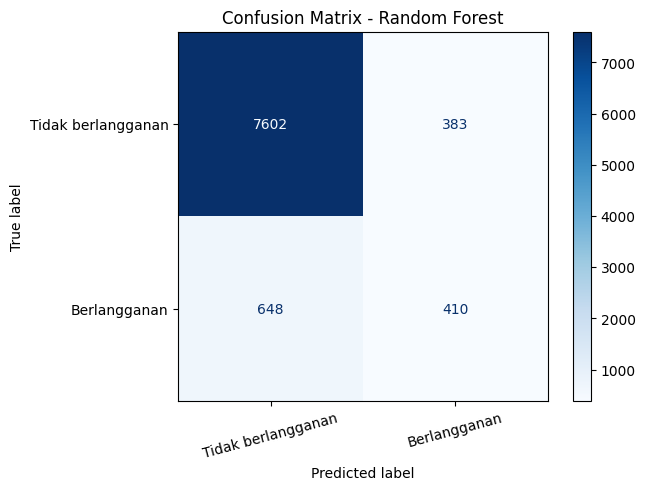

In [5]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (yes)': precision_score(y_test, pred, zero_division=0),
        'Recall (yes)': recall_score(y_test, pred, zero_division=0),
        'F1-score (yes)': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('F1-score (yes)', ascending=False)
display(results_df.round(4))

best_name = results_df.index[0]
best_model = models[best_name]
best_pred = best_model.predict(X_test)
print('Model dengan F1-score kelas yes tertinggi:', best_name)
print('\nLaporan klasifikasi model tersebut:')
print(classification_report(y_test, best_pred, target_names=['Tidak berlangganan (no)', 'Berlangganan (yes)'], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=['Tidak berlangganan', 'Berlangganan'],
    values_format='d', cmap='Blues'
)
plt.title(f'Confusion Matrix - {best_name}')
plt.xticks(rotation=15)
plt.show()


## 9. Interpretasi hasil
Berdasarkan hasil eksekusi model pada data uji (9.043 sampel), berikut adalah analisis dan interpretasi mendalam dari hasil klasifikasi:

### A. Perbandingan Model (Random Forest vs. Logistic Regression)
* **Random Forest** memberikan performa keseluruhan yang lebih seimbang dengan **Akurasi 88,60%**, **ROC-AUC 0,8014**, serta **F1-Score untuk kelas target (`yes`) sebesar 0,4430**.
* **Logistic Regression** memiliki akurasi yang lebih rendah (75,48%) dan F1-score (0,3732). Meskipun Logistic Regression menghasilkan *recall* yang lebih tinggi untuk kelas `yes` (62,38%), hal ini mengorbankan *precision* yang sangat rendah (hanya 26,62%), sehingga menghasilkan banyak *false positive* (salah tebak nasabah tidak berminat dianggap berminat).

### B. Analisis Confusion Matrix (Random Forest)
Dari total 9.043 data uji:
1. **True Negative (TN) = 7.602**: Model berhasil memprediksi dengan benar 7.602 nasabah yang memang **tidak berlangganan**.
2. **True Positive (TP) = 410**: Model berhasil menemukan 410 nasabah yang benar-benar **berlangganan deposito**.
3. **False Positive (FP) = 383**: Model salah memprediksi 383 nasabah sebagai calon pelanggan deposito, padahal sebenarnya tidak berminat.
4. **False Negative (FN) = 648**: Ada 648 nasabah yang sebenarnya berpotensi berlangganan, tetapi luput/terlewat dari prediksi model.

### C. Implikasi Bisnis (Dampak untuk Bank)
* **Pentingnya Metrik F1-Score & ROC-AUC:** Karena dataset ini tergolong *imbalanced* (jumlah nasabah yang menolak jauh lebih dominan daripada yang mau berlangganan), nilai akurasi tinggi (88,60%) dipicu oleh dominasi kelas mayoritas (`no`). Oleh karena itu, kecerdasan model dinilai dari F1-Score (0,4430) dan ROC-AUC (0,8014).
* **Efisiensi Biaya Operasional (Precision = 51,70%):** Dengan Random Forest, lebih dari separuh (51,7%) nasabah yang diprediksi akan berlangganan terbukti benar-benar mengambil deposit. Ini menghemat biaya telemarketing dan waktu agen telepon dibandingkan menghubungi nasabah secara acak.
* **Potensi Peluang Terlewat (Recall = 38,75%):** Nilai recall menunjukkan bahwa model baru bisa menangkap sekitar 38,75% dari total nasabah yang berpotensi berlangganan. Untuk meningkatkan recall di masa depan, bank dapat melakukan penyesuaian ambang batas keputusan (*decision threshold tuning*) atau teknik penyeimbangan data (*resampling/SMOTE*).

## 10. Kesimpulan dan manfaat
### A. Kesimpulan
1. **Penerapan Algoritma:** Studi kasus ini berhasil membangun dan membandingkan model klasifikasi biner (*Random Forest* dan *Logistic Regression*) untuk memprediksi potensi nasabah berlangganan deposito berjangka menggunakan dataset *Bank Marketing* (45.211 data).
2. **Model Terbaik:** **Random Forest Classifier** terbukti menjadi model dengan kinerja terbaik, menghasilkan **Akurasi 88,60%**, **ROC-AUC 0,8014**, dan **F1-Score (kelas `yes`) sebesar 0,4430** pada 9.043 data uji.
3. **Pencegahan Data Leakage:** Penanganan pra-pemrosesan dengan mengeluarkan fitur `duration` (durasi panggilan) berhasil menghasilkan model prediksi pra-kampanye yang realistis dan bebas dari kebocoran informasi masa depan (*data leakage*).
4. **Performa Klasifikasi:** Pada data uji, model Random Forest berhasil mengidentifikasi **410 nasabah potensial (True Positive)** dengan *Precision* mencapai 51,70%, jauh lebih efisien dibandingkan tebakan acak maupun model Logistic Regression.

### B. Manfaat
1. **Efisiensi Pemasaran Telemarketing:** Bank dapat menggunakan model ini untuk melakukan *screening* awal dan menyaring nasabah berisiko rendah (*unlikely to subscribe*), sehingga tim *telemarketing* dapat memfokuskan panggilan hanya pada nasabah berpotensi tinggi.
2. **Penghematan Biaya Operasional:** Dengan menekan jumlah panggilan acak (*cold calling*), bank dapat menghemat waktu agen telepon, menurunkan biaya komunikasi, dan mengurangi dampak kelelahan/gangguan kenyamanan bagi nasabah yang tidak berminat.
3. **Alat Pendukung Keputusan (*Decision Support System*):** Hasil prediksi model berfungsi sebagai alat bantu navigasi strategi kampanye, membantu divisi pemasaran menyusun prioritas penawaran deposito berdasarkan profil riwayat finansial dan kontak nasabah secara terukur.

## 11. Referensi
1. Moro, S., Cortez, P., & Rita, P. (2014). A Data-Driven Approach to Predict the Success of Bank Telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
2. UCI Machine Learning Repository. (2012). *Bank Marketing* [Dataset]. https://archive.ics.uci.edu/dataset/222/bank
